# Changing a crystal with DISCUS: substitution, vacancies, thermal noise and waves

DISCUS has commands that change a crystal in place: replace atoms at random, swap or delete single atoms, shake
every atom by its thermal displacement, or impose a modulation wave. `discuspdf.discus_ops` wraps them as typed
Python steps. A `StructureJob` reads a crystal into DISCUS, applies the steps in order, saves the result and reads
it back as a discuspdf `Structure`, so it can be analysed or passed on.

1. **A job from a unit cell** — the ideal copper crystal, read and saved unchanged.
2. **Random substitution** — 25 % of the Cu atoms become Au; the same seed gives the same crystal.
3. **Single-atom edits** — swap or replace individual atoms, starting from a `.stru` file.
4. **Vacancies** — removed atoms stay in the file as `VOID`; `purge` drops them.
5. **Thermal displacements** — random shifts whose size follows the atoms' B values; a job that starts from
   the result of another.
6. **Displacement waves** — longitudinal and transverse.
7. **Density waves** — a composition that varies along a direction.
8. **Commands without a typed step, and the seed rule.**
9. **A combined model and its diffuse scattering** — alloy + wave + thermal noise, and what each adds to an
   hk0 plane of reciprocal space.

All crystals are small (864–2048 atoms). **Every section runs DISCUS** (a few seconds per run); the generated
macro is printed before each run. Jobs run through the same `SuiteRunner` as in notebook 11, so each run keeps its
macro, inputs and `status.json` in its own folder. The steps are described in more detail in `docs/DISCUS_OPS.md`.

In [1]:
from pathlib import Path
import os, sys, json, platform, tempfile
sys.path.insert(0, str(Path.cwd().parent))
os.chdir(Path.cwd().parent)                     # repository root, like the other notebooks

import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 72
from discuspdf import read_stru, label_sites_by_slot, Lattice
from discuspdf.engine import Engine
from discuspdf.suite_runner import SuiteRunner
from discuspdf.fourier_macro import Seed, StructureSource
from discuspdf.discus_ops import (StructureJob, ReplaceRandom, ReplaceAtom, Switch, Remove, Purge, Thermal, Wave,
                                  Raw, ResultNotAStructure)
from discuspdf.structure_viz import plot_structure, displacement_vectors

CU = Path("tests/fixtures/discus_ops/cu_b05.cll")          # Cu fcc, a = 3.615 Å, B = 0.5 Å²
GAAS222 = Path("tests/fixtures/discus_6_23_01/gaas_222.stru")
SEED = Seed((11, 22, 33, 44, 55, 66, 77, 88))                # always all 8 values (see section 8)

# Where DISCUS runs. On Windows, DISCUS_SUITE lives in WSL; elsewhere it is on the PATH (or named by
# DISCUSPDF_ENGINE). Run folders must have no spaces in their path, so they go to C:\tmp on Windows.
if platform.system() == "Windows":
    ENGINE = Engine(("wsl.exe", "-d", os.environ.get("DISCUS_WSL_DISTRO", "Ubuntu-22.04"), "--",
                     "discus_suite", "-noautorun", "-macro"), timeout_seconds=600)
    WORK = Path(os.environ.get("DISCUSPDF_NB_WORK", r"C:\tmp\nb_suite")) / "nb12"
else:
    ENGINE = Engine.from_env(timeout_seconds=600)
    WORK = Path(os.environ.get("DISCUSPDF_NB_WORK", tempfile.mkdtemp(prefix="nb_suite_"))) / "nb12"
runner = SuiteRunner(WORK / "runs", ENGINE)
print("DISCUS_SUITE is started with:", " ".join(ENGINE.launcher))

def show_status(result):
    s = result.run.status()
    print(f"status: {s['status']}, {s.get('seconds')} s, warnings: {s.get('warnings') or 'none'}")

DISCUS_SUITE is started with: wsl.exe -d Ubuntu-22.04 -- discus_suite -noautorun -macro


## 1. A job from a unit cell

The copper unit cell file lists one atom; DISCUS applies the space group Fm-3m (4 atoms per cell) and repeats the
cell 6×6×6 times, giving 864 atoms. With no steps, the job just reads and saves the crystal. The macro is printed
first, then the job runs.

# discuspdf StructureJob
discus
read
cell cu_b05.cll,6,6,6
save result.stru
exit



status: complete, 0.408 s, warnings: none
864 atoms, supercell (6, 6, 6) | species ['CU'] | B values [0.5]


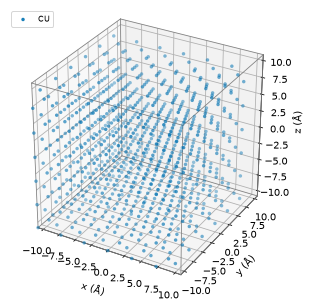

In [2]:
# StructureSource.cell(file, crystal_cells) — 'read cell <file>,n1,n2,n3': unit cell repeated n1×n2×n3
# StructureJob(source, steps=(), seed=None) — read a crystal, apply the steps in order, save result.stru
#   source    StructureSource (file given to run()) or a configuration Structure (written as input.stru)
#   seed      Seed (8 values), written right after reading; required when a step draws random numbers
job = StructureJob(StructureSource.cell("cu_b05.cll", (6, 6, 6)))
print(job.macro().render())
# StructureJob.run(runner, inputs) — run with a SuiteRunner and read result.stru back
#   inputs    {name used in the macro: file}
#   returns   JobResult: .structure (discuspdf Structure), .run (the SuiteRun record), .stru (file as read)
ideal = job.run(runner, {"cu_b05.cll": CU})
show_status(ideal)
cu = ideal.structure
print(cu.n_atoms, "atoms, supercell", tuple(int(n) for n in cu.supercell), "| species", sorted(set(cu.species)),
      "| B values", sorted({float(b) for b in np.round(cu.b_iso, 6)}))
fig = plt.figure(figsize=(5, 5))
plot_structure(cu, ax=fig.add_subplot(projection="3d"), size=12);

## 2. Random substitution

`ReplaceRandom("CU", "AU", 0.25)` writes `replace CU,AU,all,0.25`: DISCUS visits every Cu atom and turns it into
Au with probability 0.25. The number of Au atoms is therefore random, scattering around 0.25 × 864 = 216 with a
standard deviation of √(864 · 0.25 · 0.75) ≈ 12.7 atoms (a fraction of ±0.015).

The job is run three times: twice with the same seed and once with a different one.

In [3]:
# ReplaceRandom(old, new, probability, site="all") — 'replace old,new,{all|site},p' (0 < p <= 1)
alloy_job = StructureJob(StructureSource.cell("cu_b05.cll", (6, 6, 6)), [ReplaceRandom("CU", "AU", 0.25)], seed=SEED)
print(alloy_job.macro().render())
a1 = alloy_job.run(runner, {"cu_b05.cll": CU})
a2 = alloy_job.run(runner, {"cu_b05.cll": CU})
other = StructureJob(StructureSource.cell("cu_b05.cll", (6, 6, 6)), [ReplaceRandom("CU", "AU", 0.25)],
                     seed=Seed((1, 2, 3, 4, 5, 6, 7, 8))).run(runner, {"cu_b05.cll": CU})
show_status(a1)

N = a1.structure.n_atoms
sigma = np.sqrt(0.25 * 0.75 / N)
for label, r in [("seed A, run 1", a1), ("seed A, run 2", a2), ("seed B", other)]:
    x = np.mean(r.structure.species == "AU")
    print(f"{label:14s} Au fraction {x:.4f}  ({(x - 0.25) / sigma:+.2f} σ from 0.25)")
print("seed A twice, identical crystals:", np.array_equal(a1.structure.species, a2.structure.species))
print("seed A vs seed B, identical:     ", np.array_equal(a1.structure.species, other.structure.species))
print("Au atoms keep the Cu B value:", sorted({float(b) for b in np.round(a1.structure.b_iso[a1.structure.species == "AU"], 6)}))

# discuspdf StructureJob
discus
read
cell cu_b05.cll,6,6,6
seed 11,22,33,44,55,66,77,88
replace CU,AU,all,0.25
save result.stru
exit



status: complete, 0.402 s, warnings: none
seed A, run 1  Au fraction 0.2662  (+1.10 σ from 0.25)
seed A, run 2  Au fraction 0.2662  (+1.10 σ from 0.25)
seed B         Au fraction 0.2604  (+0.71 σ from 0.25)
seed A twice, identical crystals: True
seed A vs seed B, identical:      False
Au atoms keep the Cu B value: [0.5]


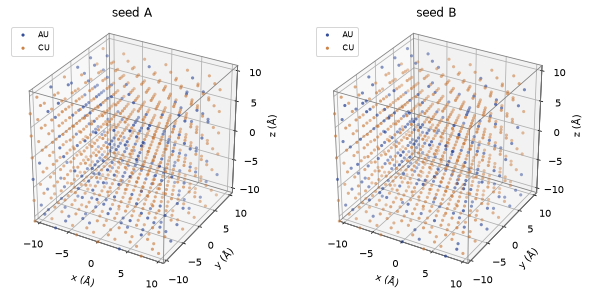

In [4]:
fig = plt.figure(figsize=(10, 4.5))
for k, (label, r) in enumerate([("seed A", a1), ("seed B", other)]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    plot_structure(r.structure, ax=ax, size=10, colors={"CU": "#c87533", "AU": "#1f3b8f"})
    ax.set_title(label)

## 3. Single-atom edits, from a `.stru` file

A job can also start from a `.stru` file (`read stru`). This GaAs file holds a 2×2×2 crystal (64 atoms) but no
`ncell` line, so the crystal size is given. `Switch(1, 5)` swaps the chemistry of atoms 1 (Ga) and 5 (As), an
antisite pair; their positions stay. `ReplaceAtom(2, "IN", b=0.5)` puts an indium atom on site 2; a new atom type
needs its B value. Atom numbers are DISCUS's, counted from 1.

In [5]:
before = read_stru(GAAS222, supercell=(2, 2, 2)).structure
# Switch(i, j) — 'switch i,j';  ReplaceAtom(index, atom, b=None) — 'replace index,atom[,b]'
edit = StructureJob(StructureSource.stru("gaas_222.stru", crystal_cells=(2, 2, 2)),
                    [Switch(1, 5), ReplaceAtom(2, "IN", b=0.5)])
print(edit.macro().render())
after = edit.run(runner, {"gaas_222.stru": GAAS222})
show_status(after)
print("atom   before  after   B after")
for i in range(8):
    print(f"{i + 1:4d}   {before.species[i]:6s}  {after.structure.species[i]:6s}  {after.structure.b_iso[i]:.3f}")
print("composition after:", {s: int((after.structure.species == s).sum()) for s in sorted(set(after.structure.species))})

# discuspdf StructureJob
discus
read
structure gaas_222.stru
switch 1,5
replace 2,IN,0.5
save result.stru
exit



status: complete, 0.389 s, warnings: none
atom   before  after   B after
   1   GA      AS      1.000
   2   GA      IN      0.500
   3   GA      GA      1.000
   4   GA      GA      1.000
   5   AS      GA      1.000
   6   AS      AS      1.000
   7   AS      AS      1.000
   8   AS      AS      1.000
composition after: {'AS': 32, 'GA': 31, 'IN': 1}


## 4. Vacancies

`Remove(3, 5)` empties atoms 3 to 5. DISCUS keeps them in the list and saves them as `VOID` atoms, so the file is
still a whole number of unit cells and reads back as a `Structure`.

`Purge()` then deletes the vacancies from the list. The crystal now has 861 atoms, which is no longer the same
number in every unit cell, so it cannot be a `Structure` of 6×6×6 cells; the job says so by raising
`ResultNotAStructure`. The file DISCUS wrote is still there.

In [6]:
# Remove(start, end=None) — 'remove start,end': atoms become vacancies but stay in the list
vac = StructureJob(StructureSource.cell("cu_b05.cll", (6, 6, 6)), [Remove(3, 5)]).run(runner, {"cu_b05.cll": CU})
show_status(vac)
s = vac.structure
print(s.n_atoms, "rows;", {sp: int((s.species == sp).sum()) for sp in sorted(set(s.species))},
      "| VOID rows:", [int(i) + 1 for i in np.flatnonzero(s.species == "VOID")])
print("columns not kept by the Structure:", vac.stru.dropped)

# Purge(types=False) — 'purge': drop the vacancies from the list
try:
    StructureJob(StructureSource.cell("cu_b05.cll", (6, 6, 6)), [Remove(3, 5), Purge()]).run(runner, {"cu_b05.cll": CU})
except ResultNotAStructure as err:
    print("\nResultNotAStructure:", str(err)[:120], "…")
    saved = err.run.output("result.stru")            # the file is kept in the run folder
    lines = saved.read_text().splitlines()
    first = next(i for i, l in enumerate(lines) if l.lower().startswith("atoms")) + 1
    print("atom rows in", saved.name, ":", sum(1 for l in lines[first:] if l.strip()),
          "| run status:", err.run.status()["status"])

status: complete, 0.405 s, warnings: none
864 rows; {'CU': 861, 'VOID': 3} | VOID rows: [3, 4, 5]
columns not kept by the Structure: ('Property',)



ResultNotAStructure: DISCUS ran, but result.stru is not a (6, 6, 6) crystal: C:\tmp\nb_suite_013\nb12\runs\20261104T005226Z_948fd566\result.s …
atom rows in result.stru : 861 | run status: complete


## 5. Thermal displacements, from the result of another job

`Thermal()` writes `thermal`: DISCUS moves every atom by a random Gaussian amount in each Cartesian direction,
with a spread set by its B value: σ² = B / 8π². For Cu here, B = 0.5 Å², so σ² = 0.00633 Å² (σ ≈ 0.080 Å).

Here the job starts from a **discuspdf `Structure`** — the ideal crystal of section 1 — instead of a file; the job
writes it as `input.stru`. The displacements are measured against the same ideal crystal.

# discuspdf StructureJob
discus
read
structure input.stru
seed 11,22,33,44,55,66,77,88
thermal
save result.stru
exit



status: complete, 0.412 s, warnings: none
expected <u²> per direction: 0.00633 Å²
  measured <u_x²> = 0.00654 Å²   mean u_x = -0.0034 Å
  measured <u_y²> = 0.00565 Å²   mean u_y = +0.0006 Å
  measured <u_z²> = 0.00650 Å²   mean u_z = -0.0003 Å


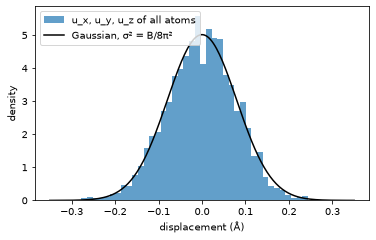

In [7]:
# A configuration Structure as source: written as input.stru, read with 'read stru'
th = StructureJob(cu, [Thermal()], seed=SEED)
print(th.macro().render())
th = th.run(runner)
show_status(th)

# displacement_vectors(configuration, reference) — (reference positions, displacements) in Å, matched by
#   (site label, cell); label_sites_by_slot numbers the sites by their order in the cell, as DISCUS does
ref = label_sites_by_slot(cu)
_, u = displacement_vectors(label_sites_by_slot(th.structure), ref)
expected = 0.5 / (8 * np.pi ** 2)
print("expected <u²> per direction: %.5f Å²" % expected)
for k, axis in enumerate("xyz"):
    print(f"  measured <u_{axis}²> = {np.mean(u[:, k] ** 2):.5f} Å²   mean u_{axis} = {u[:, k].mean():+.4f} Å")
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(u.ravel(), bins=40, density=True, alpha=0.7, label="u_x, u_y, u_z of all atoms")
g = np.linspace(-0.35, 0.35, 200)
ax.plot(g, np.exp(-g ** 2 / (2 * expected)) / np.sqrt(2 * np.pi * expected), "k", label="Gaussian, σ² = B/8π²")
ax.set(xlabel="displacement (Å)", ylabel="density"); ax.legend();

**What you see.** The histogram follows the Gaussian, and the three measured ⟨u²⟩ scatter around B/8π². With 864
atoms, each of them has a statistical uncertainty of about ±5 % (σ²·√(2/864)), so differences of up to about 10 %
between directions are expected from one random crystal.

## 6. Displacement waves

`Wave` writes the DISCUS `waves` menu. A **longitudinal** wave moves atoms along the wave vector, a
**transverse** wave across it (along `oscillation`). Here both run along a = (1, 0, 0) with a wavelength of
10.845 Å (3 unit cells, so the 6-cell crystal holds exactly two periods) and an amplitude of 0.1 Å. The profile
`sinus` is amplitude · cos(2π · position / wavelength + phase).

In [8]:
# Wave(kind, vector, length, function="sinus", amplitude=…, phase=0, oscillation=…, select="all", …)
#   kind         "longitudinal", "transverse" (needs oscillation) or "density" (section 7)
#   vector       wave vector in lattice units (only its direction is used);  length  wavelength in Å
#   amplitude    displacement amplitude in Å;  phase  degrees or "random"
lam, amp = 3 * 3.615, 0.1
waves = {"longitudinal": Wave("longitudinal", (1, 0, 0), lam, amplitude=amp),
         "transverse": Wave("transverse", (1, 0, 0), lam, amplitude=amp, oscillation=(0, 1, 0))}
print(StructureJob(cu, [waves["transverse"]]).macro().render())
moved = {kind: StructureJob(cu, [w]).run(runner) for kind, w in waves.items()}
for kind, r in moved.items():
    print(kind, end=": "); show_status(r)

# discuspdf StructureJob
discus
read
structure input.stru
waves
reset
transverse
accoustic
function sinus
length 10.845
amplitude 0.1
vector 1,0,0
phase 0
osci 0,1,0
select all
run
exit
save result.stru
exit



longitudinal: status: complete, 0.398 s, warnings: none
transverse: status: complete, 0.421 s, warnings: none


longitudinal fitted amplitude 0.1000 Å, phase +0.0°; largest |u| across the wave direction: 0.00e+00 Å
transverse   fitted amplitude 0.1000 Å, phase +0.0°; largest |u| across the wave direction: 6.12e-18 Å


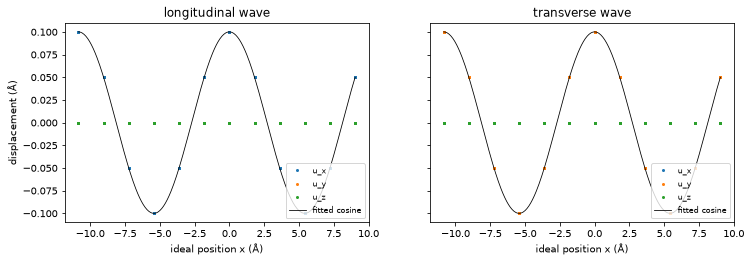

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, (kind, r) in zip(axes, moved.items()):
    x0, u = displacement_vectors(label_sites_by_slot(r.structure), ref)
    for k, axis in enumerate("xyz"):
        ax.plot(x0[:, 0], u[:, k], ".", ms=4, label=f"u_{axis}")
    # least-squares cosine through the measured displacement along the expected direction
    k = 0 if kind == "longitudinal" else 1
    M = np.column_stack([np.cos(2 * np.pi * x0[:, 0] / lam), np.sin(2 * np.pi * x0[:, 0] / lam)])
    c, s = np.linalg.lstsq(M, u[:, k], rcond=None)[0]
    print(f"{kind:12s} fitted amplitude {np.hypot(c, s):.4f} Å, phase {np.degrees(np.arctan2(-s, c)):+.1f}°;"
          f" largest |u| across the wave direction: {np.abs(np.delete(u, k, axis=1)).max():.2e} Å")
    xs = np.linspace(x0[:, 0].min(), x0[:, 0].max(), 300)
    ax.plot(xs, c * np.cos(2 * np.pi * xs / lam) + s * np.sin(2 * np.pi * xs / lam), "k-", lw=0.8, label="fitted cosine")
    ax.set(title=f"{kind} wave", xlabel="ideal position x (Å)"); ax.legend(loc="lower right", fontsize="small")
axes[0].set_ylabel("displacement (Å)");

**What you see.** In each panel one component follows a cosine of period 10.845 Å and the other two stay at zero:
u_x for the longitudinal wave, u_y for the transverse one. The fitted amplitude is the requested 0.1 Å.

## 7. Density waves

A density wave changes the chemistry instead of the positions. The wave profile f runs between `plow` and
`phigh`, and DISCUS replaces an atom of type `from` by `to` when a random number exceeds f, i.e. with probability
**1 − f** (`waves.f90`). With `plow=0.2`, `phigh=0.8` the Au probability therefore swings between 0.2 and 0.8 along
the wave. The crystal has 12 atomic layers along a (72 atoms each); each layer's Au fraction is plotted.

# discuspdf StructureJob
discus
read
structure input.stru
seed 11,22,33,44,55,66,77,88
waves
reset
density
function sinus
length 10.845
vector 1,0,0
phase 0
plow 0.2
phigh 0.8
replace CU,AU
run
exit
save result.stru
exit



status: complete, 0.396 s, warnings: none
overall Au fraction: 0.499 | atoms per layer: 72


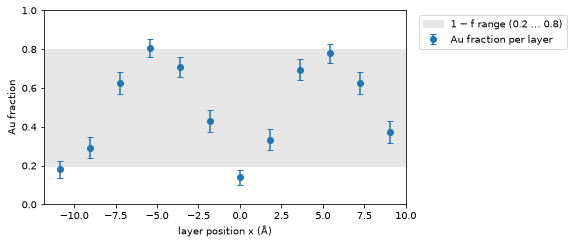

In [10]:
dens = StructureJob(cu, [Wave("density", (1, 0, 0), lam, replace=("CU", "AU"), plow=0.2, phigh=0.8)], seed=SEED)
print(dens.macro().render())
dens = dens.run(runner)
show_status(dens)
x = np.round(ref.cartesian[:, 0], 4)
layers = np.unique(x)
au = np.array([np.mean(dens.structure.species[x == xl] == "AU") for xl in layers])
n_layer = np.sum(x == layers[0])
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.errorbar(layers, au, yerr=np.sqrt(au * (1 - au) / n_layer), fmt="o", capsize=3, label="Au fraction per layer")
ax.axhspan(1 - 0.8, 1 - 0.2, color="0.9", label="1 − f range (0.2 … 0.8)")
ax.set(xlabel="layer position x (Å)", ylabel="Au fraction", ylim=(0, 1))
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
print("overall Au fraction:", round(float(np.mean(dens.structure.species == "AU")), 3), "| atoms per layer:", n_layer)

**What you see.** The Au fraction rises and falls with the period of the wave between about 0.2 and 0.8 (the grey
band), with the statistical scatter of 72 atoms per layer (error bars).

## 8. Commands without a typed step, and the seed rule

The steps above cover the most common DISCUS commands, but DISCUS has many more (copying or inserting atoms,
symmetry operations, and so on). `Raw` lets you use any of them in a job: you write the line exactly as you would
in a DISCUS macro, and the job puts it between reading the crystal and saving it, in order with the other steps.

discuspdf does not interpret the line, so what it does to the crystal is up to you. The one check is that the
command exists: the line is looked up in the command catalogue of notebook 11, so a misspelt command is refused
before anything runs. If the command leaves a different number of atoms in some unit cells (for example by adding
an atom), the result can no longer be read back as a `Structure`, and the job raises `ResultNotAStructure` as in
section 4.

The cell below runs a small job: a typed step replaces atom 2 by gold, then a raw line, `show atom,1,4`, asks
DISCUS to list the first four atoms. DISCUS answers in the run's log (`run.log`), where it repeats every macro
line as `discus> …`; the cell prints the lines that follow the raw command. The answer already shows the gold
atom, because the steps run in order. Then the cell tries a command that does not exist.

In [ ]:
import re
from discuspdf.macro import MacroError
# Raw(lines, random=False) — lines written unchanged in the DISCUS main menu; random=True if they draw
#   random numbers, so the job insists on a seed
job = StructureJob(StructureSource.cell("cu_b05.cll", (2, 2, 2)), [ReplaceAtom(2, "AU", b=0.5), Raw(("show atom,1,4",))])
print(job.macro().render())
shown = job.run(runner, {"cu_b05.cll": CU})
show_status(shown)

# DISCUS repeats each macro line in run.log as 'discus> <line>'; its answer is what follows, up to the next line
log = (shown.run.directory / "run.log").read_text(errors="replace").splitlines()
log = [re.sub(r"\x1b\[[0-9;]*m", "", line).rstrip() for line in log]       # drop terminal colour codes
start = next(i for i, line in enumerate(log) if line.strip() == "discus> show atom,1,4")
answer = []
for line in log[start + 1:]:
    if line.strip().startswith("discus>"):
        break
    answer.append(line)
print("\nDISCUS's answer to 'show atom,1,4':")
print("\n".join(answer))

try:
    StructureJob(StructureSource.cell("cu_b05.cll", (2, 2, 2)), [Raw(("frobnicate 1",))]).macro().render()
except MacroError as exc:
    print("\nrefused:", exc)

Without an explicit seed, DISCUS seeds its random numbers from the clock, and a run cannot be repeated. A job
with a step that draws random numbers (`ReplaceRandom`, `Thermal`, a density wave, a random phase,
`Raw(..., random=True)`) is therefore refused without `seed=`. `allow_unseeded=True` overrides this on purpose.
A seed must have all 8 values: with a single value, DISCUS still takes the other seed words from the clock.

In [12]:
try:
    StructureJob(StructureSource.cell("cu_b05.cll", (6, 6, 6)), [Thermal()])
except ValueError as exc:
    print("ValueError:", exc)
unseeded = StructureJob(StructureSource.cell("cu_b05.cll", (6, 6, 6)), [Thermal()], allow_unseeded=True)
print("allowed with allow_unseeded=True; macro has a seed line:", "seed" in unseeded.macro().render())

ValueError: Thermal draws random numbers; give seed=Seed(...) (without one DISCUS seeds from the clock), or allow_unseeded=True
allowed with allow_unseeded=True; macro has a seed line: False


## 9. A combined model and its diffuse scattering

Steps combine, and jobs chain. Here a Cu₃Au-like random alloy (8×8×8 cells, 2048 atoms) is built in three
stages, each job starting from the previous result:

1. random alloy, 25 % Au;
2. plus a longitudinal displacement wave along a (wavelength 4 cells = 14.46 Å, amplitude 0.08 Å);
3. plus thermal displacements (B = 0.5 Å²).

For each stage, DISCUS computes the X-ray scattering in the hk0 plane (h, k from −4 to 4 in steps of 1/16) with
the Fourier tools of notebook 07. `set aver 100` subtracts the average structure's contribution, so the sharp
Bragg peaks are removed and only the **diffuse** scattering — from the departures from the average — is left.

In [13]:
cu_lattice = Lattice.from_parameters(3.615, 3.615, 3.615, 90, 90, 90)
stage_steps = {"alloy": [ReplaceRandom("CU", "AU", 0.25)],
               "+ wave": [Wave("longitudinal", (1, 0, 0), 4 * 3.615, amplitude=0.08)],
               "+ thermal": [Thermal()]}
stages, source, inputs = {}, StructureSource.cell("cu_b05.cll", (8, 8, 8)), {"cu_b05.cll": CU}
for name, steps in stage_steps.items():
    r = StructureJob(source, steps, seed=SEED).run(runner, inputs)
    stages[name] = r
    source, inputs = r.structure, None              # the next stage starts from this crystal
    print(f"{name:10s} {r.structure.n_atoms} atoms, Au {np.mean(r.structure.species == 'AU'):.3f}", end="; ")
    show_status(r)

alloy      2048 atoms, Au 0.251; status: complete, 0.414 s, warnings: none


+ wave     2048 atoms, Au 0.251; status: complete, 0.418 s, warnings: none


+ thermal  2048 atoms, Au 0.251; status: complete, 0.44 s, warnings: none


In [14]:
from discuspdf import ReciprocalGrid, FourierConfig, SampledVolume, plot_slice, mask_near_bragg
from discuspdf.fourier_macro import prepare_fourier_run
from discuspdf.diffuse3d import Diffuse3DRunner

# ReciprocalGrid.from_corners(lattice, ll, lr, ul, tl, shape) — grid given like the DISCUS fourier menu
#   129 × 129 points: h, k from -4 to 4 in steps of 1/16; a single l = 0 layer (tl = ll)
grid = ReciprocalGrid.from_corners(cu_lattice, ll=(-4, -4, 0), lr=(4, -4, 0), ul=(-4, 4, 0), tl=(-4, -4, 0),
                                 shape=(129, 129, 1))
# FourierConfig(grid, outputs, aver_percent=0, seed=None, temperature="ignore", radiation="xray", …)
#   outputs        ((value, file.h5), ...);  aver_percent 100 removes the average structure (Bragg peaks)
#   temperature    "ignore": no Debye-Waller factor (the displacements are in the atom positions already)
config = FourierConfig(grid, outputs=(("int", "hk0.h5"),), aver_percent=100)
planes = {}
for name, r in stages.items():
    f3d = Diffuse3DRunner(WORK / "runs_3d", engine=ENGINE, output_filename="hk0.h5")
    # prepare_fourier_run(runner, config, structure, path) — stage the macro, the .stru and fourier_config.json
    frun = prepare_fourier_run(f3d, config, StructureSource.stru("result.stru", crystal_cells=(8, 8, 8)),
                               r.run.output("result.stru"), title=f"nb12 {name}")
    if name == "alloy":
        print(frun.directory.joinpath("run.mac").read_text())
    f3d.execute(frun, native_nexus=True)
    print(name, "Fourier run:", json.loads(frun.directory.joinpath("status.json").read_text())["status"])
    planes[name] = frun.load_scattering_volume()

# nb12 alloy
discus
read
  stru result.stru
eval n[1]
eval n[2]
eval n[3]
fourier
  xray
  wvle moa1
  ll -4,-4,0
  lr 4,-4,0
  ul -4,4,0
  tl -4,-4,0
  na 129
  no 129
  nt 1
  abs h
  ord k
  top l
  temp ignore
  disp off
  lots off
  set technique:turbo
  set aver,100.0
  show
  run
exit
output
  value int
  form nexus
  outf hk0.h5
  run
exit
exit
exit



alloy Fourier run: complete


+ wave Fourier run: complete


+ thermal Fourier run: complete


median background (away from satellites)     satellite on the h axis
            |hk| 0.3-1   |hk| 4-5         h=0.25    h=1.75    h=3.75
alloy         6.12e+05   2.35e+05       6.23e+05  4.42e+05  2.69e+05
+ wave        6.03e+05   2.81e+05       5.12e+06  5.52e+07  1.13e+08
+ thermal     6.54e+05   4.46e+05        4.9e+06  4.82e+07  7.91e+07


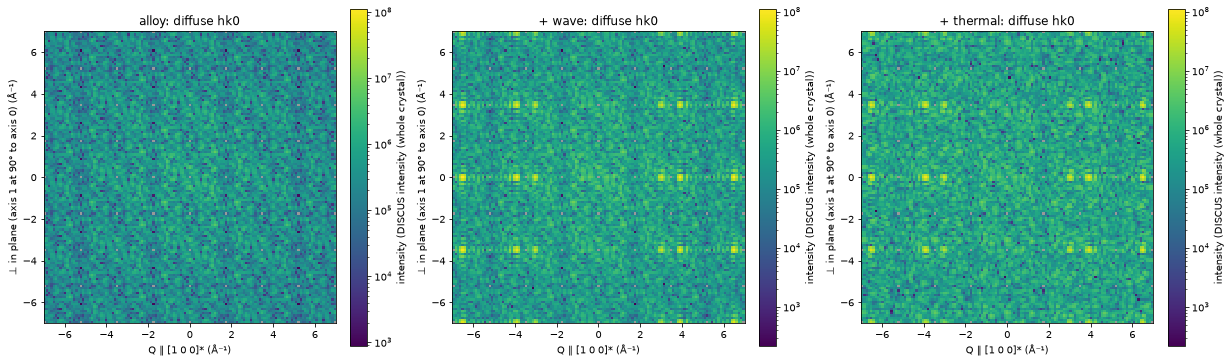

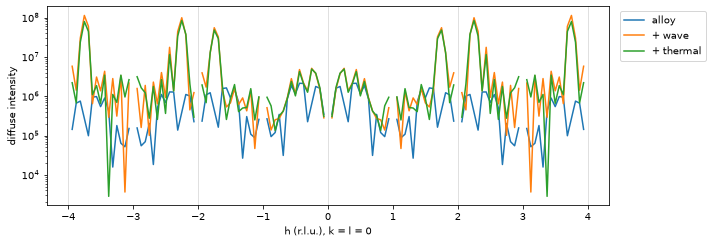

In [15]:
# mask_near_bragg(grid, radius) — True within `radius` Å⁻¹ of every integer hkl: here exactly the 81 Bragg
#   positions, where set aver 100 leaves (almost) nothing; masked points are drawn grey
# plot_slice(vol, axis, index, log=True, vmax=…) — one layer in its true geometry (Q in Å⁻¹), log colour scale
bragg = mask_near_bragg(grid, 0.05)
vmax = max(float(np.nanmax(p.intensity)) for p in planes.values())
fig, axes = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)
for ax, (name, p) in zip(axes, planes.items()):
    vol = SampledVolume.from_scattering_volume(p.with_mask(bragg, "removed Bragg positions"))
    plot_slice(vol, axis=2, index=0, log=True, vmax=vmax, ax=ax, title=f"{name}: diffuse hk0")

# a line along h at k = 0, where the longitudinal wave's satellites lie
k0 = grid.shape[1] // 2
h = grid.hkl()[:, k0, 0, 0]
fig, ax = plt.subplots(figsize=(10, 3.5))
for name, p in planes.items():
    line = p.intensity[:, k0, 0].astype(float)
    line[line < vmax * 1e-6] = np.nan                # integer-h points, where set aver leaves (almost) nothing
    ax.semilogy(h, line, label=name)
for hb in (-4, -2, 0, 2, 4):                        # fcc Bragg positions on this line
    ax.axvline(hb, color="0.85", lw=0.8, zorder=0)
ax.set(xlabel="h (r.l.u.), k = l = 0", ylabel="diffuse intensity")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()

# numbers behind the pictures: background away from the satellites, and satellite heights on the h axis
H, K = np.meshgrid(h, h, indexing="ij")
Qr = np.hypot(H, K)
off_grid = (np.abs(H - np.round(H)) > 1e-9) | (np.abs(K - np.round(K)) > 1e-9)
near_sat = np.zeros_like(off_grid)
for hb in (-4, -2, 0, 2, 4):
    for kb in (-4, -2, 0, 2, 4):
        for dh in (-0.25, 0.25):
            near_sat |= (np.abs(H - hb - dh) < 0.07) & (np.abs(K - kb) < 0.07)
print("median background (away from satellites)     satellite on the h axis")
print(f"{'':10s} {'|hk| 0.3-1':>11s} {'|hk| 4-5':>10s}      {'h=0.25':>9s} {'h=1.75':>9s} {'h=3.75':>9s}")
for name, p in planes.items():
    I = p.intensity[:, :, 0]
    bg = [np.median(I[off_grid & ~near_sat & (Qr >= lo) & (Qr < hi)]) for lo, hi in ((0.3, 1), (4, 5))]
    sat = [I[int(round((hs + 4) * 16)), k0] for hs in (0.25, 1.75, 3.75)]
    print(f"{name:10s} {bg[0]:11.3g} {bg[1]:10.3g}      " + " ".join(f"{v:9.3g}" for v in sat))

**What you see.** The maps are drawn in Q (Å⁻¹); for this cell one step in h or k is 2π/3.615 Å = 1.74 Å⁻¹.
The line plot and the table use h.

* **Alloy.** The random distribution of Cu and Au gives a featureless background (Laue diffuse scattering) that
  falls off with Q as the atomic form factors do (from about 6·10⁵ near the centre to 2·10⁵ at the edge in the
  table). It looks grainy because this is one random crystal of 2048 atoms, not an average over many. There are no
  peaks, since the atoms are uncorrelated, and the intensity is zero at whole-number h and k, where
  `set aver 100` removes the average structure (masked, grey dots).
* **+ wave.** The wave adds sharp satellites at h ± 1/4 next to the Bragg positions (for fcc, h and k both even
  in this plane), displaced along h because the wave vector is along a and its period is 4 cells. Their strength
  grows with h, because a displacement u is seen through Q · u: on the h axis they rise from about 5·10⁶ at
  h = 0.25 to 10⁸ at h = 3.75, far above the background.
* **+ thermal.** Random thermal shifts add a broad diffuse background that grows with Q (about ∝ Q²⟨u²⟩): the
  background rises by under 10 % near the centre and by about 60 % at the edge, compared with the wave stage. They
  also weaken the satellites, the more the larger Q is (by about 30 % at h = 3.75).

## Things to keep in mind

* **The crystal size comes from the source.** DISCUS `save` writes no `ncell` line, so the job takes the size
  from the `read cell` counts, the `ncell` line of an input `.stru`, the `crystal_cells` you give, or
  `Structure.supercell`.
* **Large displacements.** The read-back checks DISCUS's cell-major atom order. After displacements of more than
  half a cell, use `run(..., check_order=False)`.
* **New atom types** take the B value of the type they replace (`ReplaceRandom`) or need `b=` (`ReplaceAtom`).
  DISCUS reads B < 0.001 as 1.0.
* **Waves**: only the direction of the wave vector counts; atom modes only (no molecules, no rotations).
* **The steps build models.** They say nothing about whether a model matches a real material; compare its
  scattering with data for that.